In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix
import joblib
import os

print("Libraries loaded!")

Libraries loaded!


In [2]:
#load dataset
print("Loading dataset...")

orders = pd.read_csv("data/orders.csv")
order_products = pd.read_csv("data/order_products__train.csv")
products = pd.read_csv("data/products.csv")
aisles = pd.read_csv("data/aisles.csv")
departments = pd.read_csv("data/departments.csv")

print(f"Orders: {len(orders):,}")
print(f"Order products: {len(order_products):,}")
print(f"Products: {len(products):,}")
print(f"Aisles: {len(aisles):,}")
print(f"Departments: {len(departments):,}")

Loading dataset...
Orders: 3,421,083
Order products: 1,384,617
Products: 49,688
Aisles: 134
Departments: 21


In [3]:
#explore dataset
print("=== Orders Sample ===")
display(orders.head())

print("\n=== Order Products Sample ===")
display(order_products.head())

print("\n=== Products Sample ===")
display(products.head())

=== Orders Sample ===


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0



=== Order Products Sample ===


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1



=== Products Sample ===


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


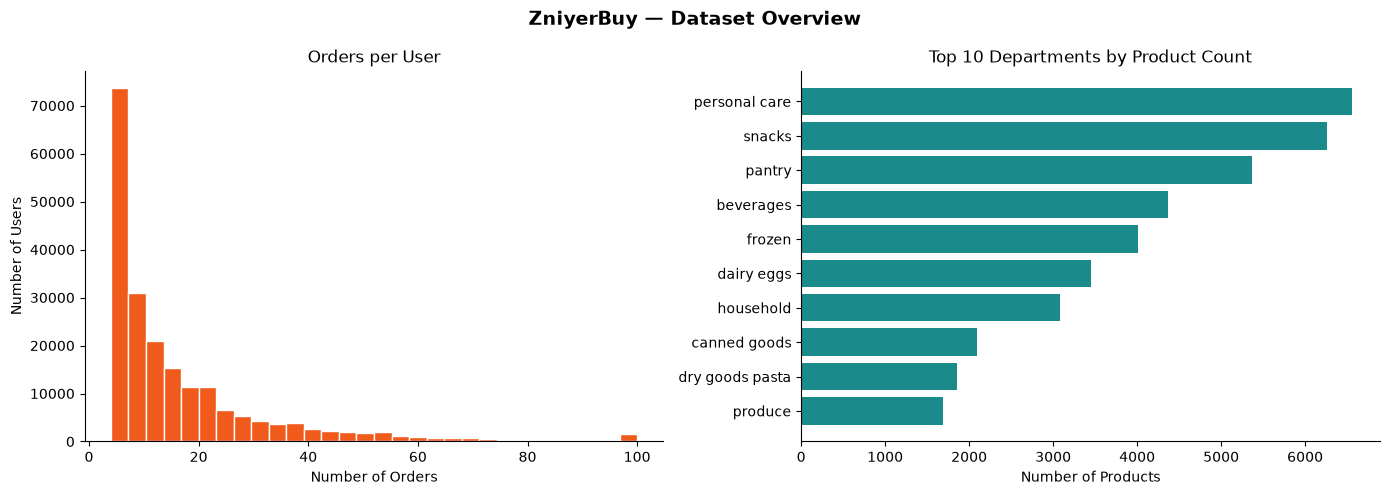

Chart saved!


In [4]:
#data visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("ZniyerBuy — Dataset Overview", fontsize=14, fontweight="bold")

# Orders per user
orders_per_user = orders.groupby("user_id")["order_id"].count()
axes[0].hist(orders_per_user, bins=30, color="#f05a1a", edgecolor="white")
axes[0].set_title("Orders per User")
axes[0].set_xlabel("Number of Orders")
axes[0].set_ylabel("Number of Users")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Top 10 departments
dept_products = products.merge(departments, on="department_id")
dept_counts = dept_products["department"].value_counts().head(10)
axes[1].barh(dept_counts.index, dept_counts.values, color="#1a8a8a")
axes[1].set_title("Top 10 Departments by Product Count")
axes[1].set_xlabel("Number of Products")
axes[1].invert_yaxis()
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("models/chart_data_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved!")

In [5]:
#preprocess data
print("Preprocessing data...")

# Merge orders with order_products to get user_id
order_products_users = order_products.merge(
    orders[["order_id", "user_id"]], on="order_id"
)

# Create user-product interaction
user_product = order_products_users.groupby(
    ["user_id", "product_id"]
)["reordered"].sum().reset_index()

user_product.columns = ["user_id", "product_id", "rating"]

# Filter top 5000 users and top 500 products
top_users = user_product.groupby("user_id")["rating"].count().nlargest(5000).index
top_products = user_product.groupby("product_id")["rating"].count().nlargest(500).index

user_product = user_product[
    (user_product["user_id"].isin(top_users)) &
    (user_product["product_id"].isin(top_products))
]

print(f"Total interactions: {len(user_product):,}")
print(f"Total users: {user_product['user_id'].nunique():,}")
print(f"Total products: {user_product['product_id'].nunique():,}")
display(user_product.head(10))

Preprocessing data...
Total interactions: 67,097
Total users: 4,989
Total products: 500


,user_id,product_id,rating
13,2,5450,1
15,2,7963,1
16,2,9387,0
22,2,19019,0
25,2,22825,1
26,2,22963,1
27,2,24838,0
28,2,24852,1
36,2,41787,1
37,2,45066,1


In [6]:
#build user-product matrix
print("Building user-product matrix...")

user_product_matrix = user_product.pivot_table(
    index="user_id",
    columns="product_id",
    values="rating",
    fill_value=0
)

print(f"Matrix shape: {user_product_matrix.shape}")

# Calculate sparsity
total = user_product_matrix.shape[0] * user_product_matrix.shape[1]
filled = (user_product_matrix > 0).sum().sum()
sparsity = (1 - filled / total) * 100
print(f"Sparsity: {sparsity:.2f}%")

display(user_product_matrix.iloc[:5, :5])

Building user-product matrix...
Matrix shape: (4989, 500)
Sparsity: 98.06%


product_id,45,196,260,329,432
user_id,,,,,
2,0.0,0.0,0.0,0.0,0.0
43,0.0,0.0,0.0,0.0,0.0
91,0.0,0.0,0.0,0.0,0.0
197,0.0,0.0,0.0,0.0,0.0
214,0.0,0.0,0.0,0.0,0.0


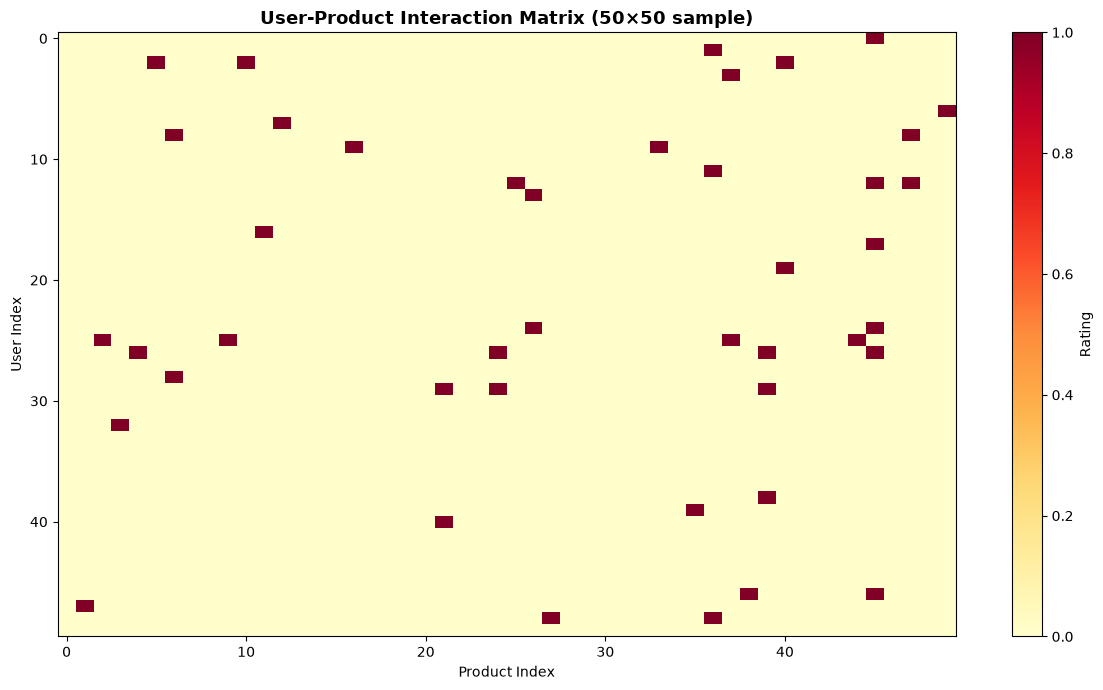

Chart saved!


In [7]:
#Matrix heatmap visualization
fig, ax = plt.subplots(figsize=(12, 7))
sample = user_product_matrix.iloc[:50, :50]
im = ax.imshow(sample.values, aspect="auto", cmap="YlOrRd", interpolation="nearest")
plt.colorbar(im, ax=ax, label="Rating")
ax.set_title("User-Product Interaction Matrix (50×50 sample)", fontsize=13, fontweight="bold")
ax.set_xlabel("Product Index")
ax.set_ylabel("User Index")
plt.tight_layout()
plt.savefig("models/chart_matrix_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved!")

In [8]:
#train model
print("Training KNN Collaborative Filtering model...")

matrix_sparse = csr_matrix(user_product_matrix.values)

model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=10,
    n_jobs=-1
)

model.fit(matrix_sparse)
print("Model trained successfully!")
print(f"Algorithm: {model.algorithm}")
print(f"Metric: {model.metric}")
print(f"N neighbors: {model.n_neighbors}")

Training KNN Collaborative Filtering model...
Model trained successfully!
Algorithm: brute
Metric: cosine
N neighbors: 10


In [9]:
#evaluate model
print("Evaluating model...")

k_values = [1, 2, 3, 5, 7, 10]
precisions = []
recalls = []
test_users = 100

for k in k_values:
    precision_list = []
    recall_list = []

    for user_idx in range(test_users):
        user_vector = csr_matrix(user_product_matrix.iloc[user_idx])
        distances, indices = model.kneighbors(user_vector, n_neighbors=k+1)

        actual = set(user_product_matrix.columns[user_product_matrix.iloc[user_idx] > 0])
        if not actual:
            continue

        similar_indices = indices.flatten()[1:]
        recommended = set()
        for idx in similar_indices:
            sim_products = set(user_product_matrix.columns[user_product_matrix.iloc[idx] > 0])
            recommended.update(sim_products - actual)
            if len(recommended) >= k:
                break

        recommended = set(list(recommended)[:k])
        if not recommended:
            continue

        hits = len(actual & recommended)
        precision_list.append(hits / len(recommended))
        recall_list.append(hits / len(actual))

    precisions.append(np.mean(precision_list) if precision_list else 0)
    recalls.append(np.mean(recall_list) if recall_list else 0)
    print(f"K={k}: Precision={precisions[-1]:.4f}, Recall={recalls[-1]:.4f}")

Evaluating model...
K=1: Precision=0.0000, Recall=0.0000
K=2: Precision=0.0000, Recall=0.0000
K=3: Precision=0.0000, Recall=0.0000
K=5: Precision=0.0000, Recall=0.0000
K=7: Precision=0.0000, Recall=0.0000
K=10: Precision=0.0000, Recall=0.0000


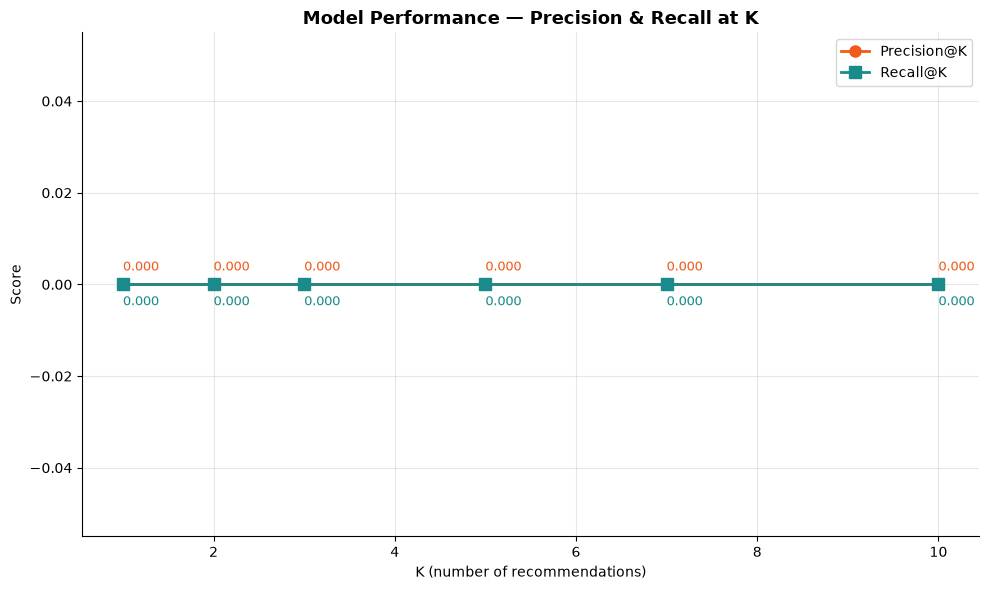

Chart saved!


In [10]:
#precision-recall curve visualization
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_values, precisions, marker="o", color="#f05a1a", linewidth=2, markersize=8, label="Precision@K")
ax.plot(k_values, recalls, marker="s", color="#1a8a8a", linewidth=2, markersize=8, label="Recall@K")
ax.set_title("Model Performance — Precision & Recall at K", fontsize=13, fontweight="bold")
ax.set_xlabel("K (number of recommendations)")
ax.set_ylabel("Score")
ax.legend()
ax.grid(True, alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for i, (p, r) in enumerate(zip(precisions, recalls)):
    ax.annotate(f"{p:.3f}", (k_values[i], p), textcoords="offset points", xytext=(0, 10), fontsize=9, color="#f05a1a")
    ax.annotate(f"{r:.3f}", (k_values[i], r), textcoords="offset points", xytext=(0, -15), fontsize=9, color="#1a8a8a")
plt.tight_layout()
plt.savefig("models/chart_precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved!")

In [11]:
#test recommendation for a specific user
def get_recommendations(user_id, top_n=5):
    if user_id not in user_product_matrix.index:
        return []
    
    user_idx = user_product_matrix.index.get_loc(user_id)
    user_vector = csr_matrix(user_product_matrix.iloc[user_idx])
    distances, indices = model.kneighbors(user_vector, n_neighbors=11)
    
    similar_indices = indices.flatten()[1:]
    already_bought = set(user_product_matrix.columns[user_product_matrix.iloc[user_idx] > 0])
    
    recommended = []
    for idx in similar_indices:
        sim_products = set(user_product_matrix.columns[user_product_matrix.iloc[idx] > 0])
        new_products = sim_products - already_bought
        for pid in new_products:
            name = products[products["product_id"] == pid]["product_name"].values
            if len(name) > 0 and name[0] not in recommended:
                recommended.append(name[0])
            if len(recommended) >= top_n:
                break
        if len(recommended) >= top_n:
            break
    
    return recommended

# Test with 3 users
for uid in [2, 5, 10]:
    recs = get_recommendations(uid)
    print(f"\nTop 5 recommendations for User {uid}:")
    for i, r in enumerate(recs, 1):
        print(f"  {i}. {r}")


Top 5 recommendations for User 2:
  1. Cage Free Brown Eggs-Large, Grade A
  2. Organic Blackberries
  3. 2% Reduced Fat DHA Omega-3 Reduced Fat Milk
  4. Fresh Cauliflower
  5. Carrots

Top 5 recommendations for User 5:

Top 5 recommendations for User 10:


In [12]:
os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/recommendation_model.pkl")
joblib.dump(user_product_matrix, "models/user_product_matrix.pkl")
joblib.dump(products, "models/products.pkl")

print("PKL files saved!")
print("  models/recommendation_model.pkl")
print("  models/user_product_matrix.pkl")
print("  models/products.pkl")

PKL files saved!
  models/recommendation_model.pkl
  models/user_product_matrix.pkl
  models/products.pkl
